True


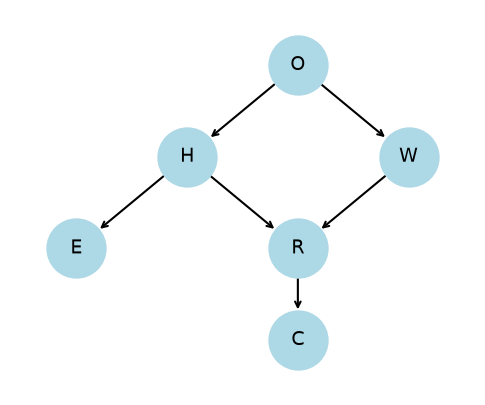

+--------+----------+
| H      |   phi(H) |
+========+==========+
| H(yes) |   0.4823 |
+--------+----------+
| H(no)  |   0.5177 |
+--------+----------+
+---------+----------+
| E       |   phi(E) |
+=========+==========+
| E(high) |   0.4894 |
+---------+----------+
| E(low)  |   0.5106 |
+---------+----------+
+--------+--------+------------+
| H      | W      |   phi(H,W) |
+========+========+============+
| H(yes) | W(yes) |     0.1138 |
+--------+--------+------------+
| H(yes) | W(no)  |     0.3684 |
+--------+--------+------------+
| H(no)  | W(yes) |     0.2776 |
+--------+--------+------------+
| H(no)  | W(no)  |     0.2401 |
+--------+--------+------------+


  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

{'H': 'yes', 'W': 'no'}
False
False


In [2]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
import networkx as nx
import matplotlib.pyplot as plt

# a) Rețeaua
model = DiscreteBayesianNetwork([('O','H'), ('O','W'), ('H','R'),
                                 ('W','R'), ('H','E'), ('R','C')])

cO = TabularCPD('O', 2, [[0.3], [0.7]], state_names={'O': ['cold','mild']})
cH = TabularCPD('H', 2, [[0.9, 0.2], [0.1, 0.8]], evidence=['O'], evidence_card=[2],
                state_names={'H': ['yes','no'], 'O': ['cold','mild']})
cW = TabularCPD('W', 2, [[0.1, 0.6], [0.9, 0.4]], evidence=['O'], evidence_card=[2],
                state_names={'W': ['yes','no'], 'O': ['cold','mild']})
cR = TabularCPD('R', 2, [[0.6, 0.9, 0.3, 0.5], [0.4, 0.1, 0.7, 0.5]],
                evidence=['H','W'], evidence_card=[2,2],
                state_names={'R': ['warm','cool'], 'H': ['yes','no'], 'W': ['yes','no']})
cE = TabularCPD('E', 2, [[0.8, 0.2], [0.2, 0.8]], evidence=['H'], evidence_card=[2],
                state_names={'E': ['high','low'], 'H': ['yes','no']})
cC = TabularCPD('C', 2, [[0.85, 0.40], [0.15, 0.60]], evidence=['R'], evidence_card=[2],
                state_names={'C': ['comfortable','uncomfortable'], 'R': ['warm','cool']})

model.add_cpds(cO, cH, cW, cR, cE, cC)
print(model.check_model())

pos = {'O': (0, 3), 'H': (-1, 2), 'W': (1, 2),
       'E': (-2, 1), 'R': (0, 1), 'C': (0, 0)}

fig, ax = plt.subplots(figsize=(6, 5))
for u, v in model.edges():
    ax.annotate("", xy=pos[v], xytext=pos[u],
                arrowprops=dict(arrowstyle="->", shrinkA=22, shrinkB=22, lw=1.5))
for n, (x, y) in pos.items():
    ax.scatter(x, y, s=1800, c='lightblue', zorder=3)
    ax.text(x, y, n, ha='center', va='center', fontsize=14, zorder=4)
ax.set_xlim(-2.6, 1.6); ax.set_ylim(-0.6, 3.6); ax.axis('off')
plt.savefig('graf.png', dpi=150, bbox_inches='tight')
plt.show()


# b) Inferență
inf = VariableElimination(model)
print(inf.query(['H'], evidence={'C': 'comfortable'}))
print(inf.query(['E'], evidence={'C': 'comfortable'}))
print(inf.query(['H','W'], evidence={'C': 'comfortable'}))
print(inf.map_query(['H','W'], evidence={'C': 'comfortable'}))

# c) d-separare (verificare)
print(model.is_dconnected('W', 'E', observed=['H']))   # False
print(model.is_dconnected('O', 'C', observed=['R']))   # False

(c) Independențe:

W ⊥ E | H: DA. E are ca unic părinte H. Orice drum de la W la E ajunge în E prin H (W←O→H→E sau W→R←H→E). Pe ambele drumuri H este nod necolider (lanț sau furcă) și este observat, deci drumurile sunt blocate. Colliderul R de pe W→R←H nu contează, fiindcă drumul trece oricum prin H.
O ⊥ C | R: DA. C are ca unic părinte R, deci orice drum de la O la C se termină cu R→C. Ambele drumuri, O→H→R→C și O→W→R→C, sunt lanțuri în care R este nod observat și necolider, deci sunt blocate.

In [3]:
import numpy as np, itertools
from hmmlearn.hmm import CategoricalHMM

# stări: 0=W, 1=R, 2=S ; observații: 0=L, 1=M, 2=H
pi = np.array([0.4, 0.3, 0.3])
A = np.array([[0.6, 0.3, 0.1],
              [0.2, 0.7, 0.1],
              [0.3, 0.2, 0.5]])
B = np.array([[0.10, 0.70, 0.20],
              [0.05, 0.25, 0.70],
              [0.80, 0.15, 0.05]])

# a) Model
model = CategoricalHMM(n_components=3, random_state=0)
model.startprob_ = pi
model.transmat_ = A
model.emissionprob_ = B

obs = np.array([[1], [2], [0]])   # M, H, L

# b) Forward
p_fwd = np.exp(model.score(obs))
print("P(M,H,L) Forward =", p_fwd)

# c) Viterbi
logp, path = model.decode(obs, algorithm="viterbi")
names = ['W', 'R', 'S']
print("Secvența:", [names[i] for i in path], "P(s*,O) =", np.exp(logp))

# d) Simulare
rng = np.random.RandomState(1)
N, cnt = 10000, 0
for _ in range(N):
    X, _ = model.sample(3, random_state=rng)
    if X.ravel().tolist() == [1, 2, 0]:
        cnt += 1
print("Empiric =", cnt / N, " Exact =", p_fwd)

P(M,H,L) Forward = 0.021117250000000008
Secvența: ['W', 'R', 'S'] P(s*,O) = 0.004703999999999999
Empiric = 0.0204  Exact = 0.021117250000000008


Rezultate:

b) P(M,H,L) = 0,0211172 (Forward)
c) Cea mai probabilă secvență: W → R → S, cu probabilitatea comună P(s*,O) = 0,004704. Viterbi e preferat enumerării brute pentru că pentru N stări și T pași enumerarea are N^T secvențe (exponențial), iar Viterbi (programare dinamică) are complexitate O(T·N²), liniară în T.
d) Probabilitatea empirică ≈ 0,0204 (10.000 secvențe) față de cea exactă 0,0211. Diferența e doar eroare de eșantionare (≈ √(p(1−p)/N) ≈ 0,0014), iar estimarea converge spre valoarea exactă când N crește.